In [1]:
import warnings
import os 
from pathlib import Path
from natsort import natsort_keygen

import pandas as pd
from pathlib import Path
import anndata as ad 
import numpy as np 
from dotenv import dotenv_values

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

warnings.simplefilter(action='ignore', category=FutureWarning)
plt.rcParams["pdf.fonttype"] = 42

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_02"
os.makedirs(OUTDIR, exist_ok=True)

SC_IN_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad'
RM_FP = DATADIR / "9_objects" / "spatial" / "regionwise_relative_masses" / "regionwise_relative_masses.csv"

In [3]:

l1_color_map = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}


In [4]:
adata = ad.read_h5ad(SC_IN_FP, backed="r")

In [5]:
labelmat = adata.obs.loc[~adata.obs.L1_ID.str.contains("NN"), [f"L{i}_descr" for i in range(1,6)]].drop_duplicates()
l2_to_l1 = labelmat.set_index("L2_descr").to_dict()["L1_descr"]
labelmat.head(2)

,L1_descr,L2_descr,L3_descr,L4_descr,L5_descr
SC1-01_SAMN18754353_AAACCCACAACCAGAG,Gl1-1 Glut,Gl2-35 VMH Nr5a1.Acvr1c,Gl3-113 VMH Cobll1,Gl4-290 VMH Cobll1.Vgll2,Gl5-390 VMH Cobll1.Vgll2
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,Gl1-1 Glut,Gl2-33 VMH Fezf1,Gl3-107 VMH Npffr1,Gl4-274 VMH Npffr1.Arhgap36,Gl5-371 VMH Npffr1.Arhgap36.Htr1b


# Preparing data and prototyping parts of the combined cluster tree plots

## Dendrogram 

### Let's build the linkage

In [6]:
subclass_labelmat = labelmat.loc[:, [f"L{i}_descr" for i in range(1,3)]]

In [7]:
def build_custom_linkage(df, level_cols):
    """
    Build a custom linkage matrix Z from a DataFrame using specified hierarchical columns.
    Supports 2 levels of hierarchy.

    Parameters:
        df: pd.DataFrame
        level_cols (list of str): List of column names defining the hierarchy from top to bottom.

    Returns:
        tuple:
            Z (np.ndarray): linkage matrix for dendrogram.
            idx_to_label (dict): mapping from leaf index to bottom-level cluster label.
    """
    assert 2 <= len(level_cols), "Function supports 2 levels of hierarchy"
    
    # Drop duplicates and sort
    df = df[level_cols].drop_duplicates().astype(str)

    key = natsort_keygen()
    df = df.sort_values(
        by=level_cols,
        key=lambda col: col.map(key)
    )

    # sort Gl before Gb or NN
    df = pd.concat([
        df.loc[df[level_cols[0]].str.contains("Gl")],
        df.loc[df[level_cols[0]].str.contains("Gb")],
        df.loc[df[level_cols[0]].str.contains("NN")]
    ], axis=0
    )

    bottom_col = level_cols[-1]
    bottom_clusters = df[bottom_col].unique()
    n_leaves = len(bottom_clusters)

    cluster_sizes = {}
    Z = []
    current_idx = 0
    merge_map = {}

    # Map bottom level clusters to leaf indices
    bottom_to_idx = {name: i for i, name in enumerate(bottom_clusters)}
    idx_to_label = {i: name for i, name in enumerate(bottom_clusters)}
    cluster_sizes = {i: 1 for i in range(n_leaves)}
    current_idx = n_leaves

    # Recursive merging from bottom-up
    for level in reversed(range(1, len(level_cols))):  # Start from second last to top
        parent_col = level_cols[level - 1]
        child_col = level_cols[level]

        merge_map_level = {}
        for parent, group in df.groupby(parent_col):
            child_clusters = group[child_col].unique()
            leaves = [
                merge_map.get(child, bottom_to_idx.get(child))
                for child in child_clusters
            ]

            # Merge all clusters under this parent
            while len(leaves) > 1:
                a = leaves.pop()
                b = leaves.pop()
                size_a = cluster_sizes[a]
                size_b = cluster_sizes[b]
                new_size = size_a + size_b
                Z.append([a, b, 0.2 + 0.1 * level, new_size])  # Distance increases with hierarchy
                cluster_sizes[current_idx] = new_size
                leaves.append(current_idx)
                current_idx += 1

            merge_map_level[parent] = leaves[0]  # Store representative for parent cluster
        merge_map = merge_map_level

    # Final root merge if needed
    final_clusters = list(merge_map.values())
    while len(final_clusters) > 1:
        a = final_clusters.pop()
        b = final_clusters.pop()
        size_a = cluster_sizes[a]
        size_b = cluster_sizes[b]
        new_size = size_a + size_b
        Z.append([a, b, 1.0, new_size])
        cluster_sizes[current_idx] = new_size
        final_clusters.append(current_idx)
        current_idx += 1

    Z = np.array(Z)
    assert Z.shape[0] + 1 == n_leaves, f"Linkage matrix Z has incorrect shape: merges={Z.shape[0]}, leaves={n_leaves}"

    return Z, idx_to_label


In [8]:
Z_subclass, idx_to_l2 = build_custom_linkage(subclass_labelmat, [f"L{i}_descr" for i in range(1,3)])
n_leaves_subclass = subclass_labelmat.L2_descr.nunique()

### Let's get a color map

In [9]:
def propagate_colors_to_deepest_level(df, level_cols, source_level_idx, cluster_color_map, default_color="#A0A0A0"):
    """
    Propagate colors from a specified source level to the deepest level in a hierarchy.

    Parameters:
        df (pd.DataFrame): DataFrame with hierarchical cluster levels as columns.
        level_cols (list of str): Ordered list of columns from top to bottom levels.
        source_level_idx (int): Index in level_cols of the source level (e.g., 0 for top).
        cluster_color_map (dict): Mapping from source level cluster names to colors.
        default_color (str): Default color to use if no mapping is found.

    Returns:
        dict: Mapping from deepest level cluster names to propagated colors.
    """
    assert 2 <= len(level_cols), "Supports 2 hierarchy levels"
    assert 0 <= source_level_idx < len(level_cols), "Invalid source level index"

    # Keep only relevant columns for mapping
    source_col = level_cols[source_level_idx]
    target_col = level_cols[-1]  # deepest level
    df_clean = df[[source_col, target_col]].drop_duplicates().astype(str)

    # Build mapping: deepest level → source level
    deep_to_source = dict(zip(df_clean[target_col], df_clean[source_col]))

    # Propagate color from source level to deepest
    deep_to_color = {
        deep: cluster_color_map.get(source, default_color)
        for deep, source in deep_to_source.items()
    }

    return deep_to_color


In [10]:
l2_to_color = propagate_colors_to_deepest_level(
    labelmat,
    level_cols=["L1_descr", "L2_descr"],
    source_level_idx=0, # propagate from 0 to last index
    cluster_color_map=l1_color_map
)


### Let's plot

In [11]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

def plot_colored_dendrogram(Z, idx_to_label, leaf_label_to_color, linewidth=1.5, default_color="#000000", **kwargs):
    """
    Plots a dendrogram with colored branches based on leaf label to color mapping.

    Parameters:
        Z (np.ndarray): Linkage matrix.
        idx_to_label (dict): Mapping from leaf index to cluster label.
        leaf_label_to_color (dict): Mapping from cluster label to color.
        linewidth (float): Width of the dendrogram lines.
        default_color (str): Color to use when multiple colors are found under a branch.
        kwargs: Additional keyword arguments passed to scipy dendrogram.
    
    Returns:
        dict: The dendrogram object returned by scipy.cluster.hierarchy.dendrogram.
    """

    # Step 1: Build leaf index to color map
    leaf_colors = {
        i: leaf_label_to_color.get(idx_to_label[i], default_color)
        for i in idx_to_label
    }

    # Step 2: Helper to trace leaves under a node
    def trace_leaves(node):
        if node < len(idx_to_label):  # It's a leaf
            return {node}
        else:
            left = int(Z[node - len(idx_to_label), 0])
            right = int(Z[node - len(idx_to_label), 1])
            return trace_leaves(left) | trace_leaves(right)

    # Step 3: Determine color for each internal node
    link_colors = {}
    for i in range(Z.shape[0]):
        a, b = int(Z[i, 0]), int(Z[i, 1])
        leaves = trace_leaves(a) | trace_leaves(b)
        colors = {leaf_colors[leaf] for leaf in leaves}
        link_colors[i + len(idx_to_label)] = (
            colors.pop() if len(colors) == 1 else default_color
        )

    # Step 4: Plot with link color function
    with plt.rc_context({'lines.linewidth': linewidth}):
        dendro = dendrogram(
            Z,
            link_color_func=lambda k: link_colors.get(k, default_color),
            labels=[idx_to_label[i] for i in range(len(idx_to_label))],
            leaf_rotation=90,
            **kwargs
        )

    return dendro


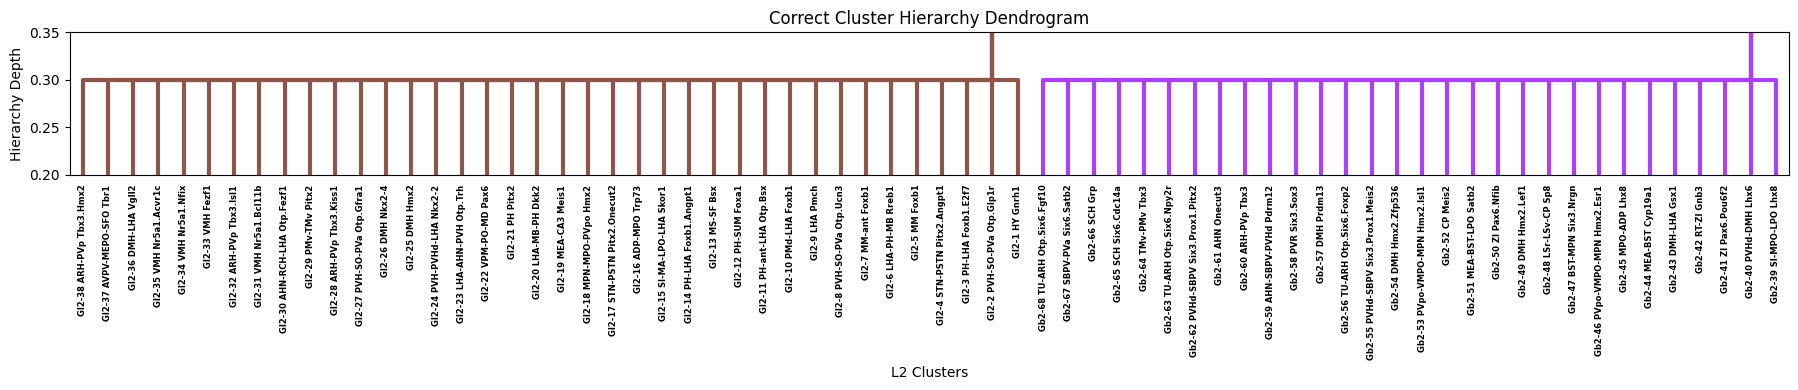

<Figure size 640x480 with 0 Axes>

In [12]:
plt.figure(figsize=(18, 4))
dendro_subclass = plot_colored_dendrogram(Z_subclass, idx_to_l2, l2_to_color, linewidth=3)

plt.title("Correct Cluster Hierarchy Dendrogram")
plt.xlabel("L2 Clusters")
plt.ylabel("Hierarchy Depth")
plt.xticks(fontweight='bold')
plt.tight_layout()
plt.ylim(0.2, 0.35)


# === Get label positions from x-axis tick labels ===# After plotting dendrogram
ax = plt.gca()
tick_labels = [tick.get_text() for tick in ax.get_xticklabels()]
tick_positions = ax.get_xticks()

label_to_x = {
    label: xpos for label, xpos in zip(tick_labels, tick_positions)
}

# plot parts above the leaves
plt.vlines(x=label_to_x["Gb2-40 PVHd-DMH Lhx6"], 
        ymin = 0.3, ymax=1,
        color=l2_to_color["Gb2-40 PVHd-DMH Lhx6"], linestyle='-', linewidth=3)

plt.vlines(x=label_to_x["Gl2-2 PVH-SO-PVa Otp.Glp1r"], 
        ymin = 0.3, ymax=1,
        color=l2_to_color["Gl2-2 PVH-SO-PVa Otp.Glp1r"], linestyle='-', linewidth=3)

#plt.gca().invert_xaxis()

plt.show()
sns.despine()


In [13]:
leaf_labels_subclass = tick_labels[::-1] #revert the order to match the plot above
#leaf_labels_subclass = [l for l in tick_labels[::-1] if "Gl2" in l] +  [l for l in tick_labels[::-1] if "Gb2" in l]#revert the order to match the plot above

## abc vs v1 vs 3D cell ratios

In [14]:
adata.obs["is_part_of"] = "New data"
adata.obs.loc[adata.obs.Dataset.str.contains("SC1"), "is_part_of"] = "Present in HypoMap (2022)"
adata.obs.loc[adata.obs.Author == "YaoZ", "is_part_of"] = "Present in Allen Brain Cell Atlas"


In [15]:
# Map authors to their assigned color
color_map_donor_subclass = {
    "Present in Allen Brain Cell Atlas": "#DDDED6",
    "Present in HypoMap (2022)": "#88B2AA",
    "New data": "#116656"
    }

In [16]:
donor_contrib_subclass = (
    adata.obs.loc[:, ["L2_descr", "is_part_of"]]
    .value_counts()
    .reset_index(name="proportion")
)

# Pivot the data to get proportions per donor for each leiden cluster
df_donor_subclass = donor_contrib_subclass.pivot(index="L2_descr", columns="is_part_of", values="proportion")

# Normalize each leiden to make it percentage (i.e. row sum = 1)
df_donor_subclass = df_donor_subclass.div(df_donor_subclass.sum(axis=1), axis=0) * 100

# Reorder clusters to match dendrogram
df_donor_subclass = df_donor_subclass.loc[leaf_labels_subclass,:]

/tmp/ipykernel_3184007/4063846963.py:13: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


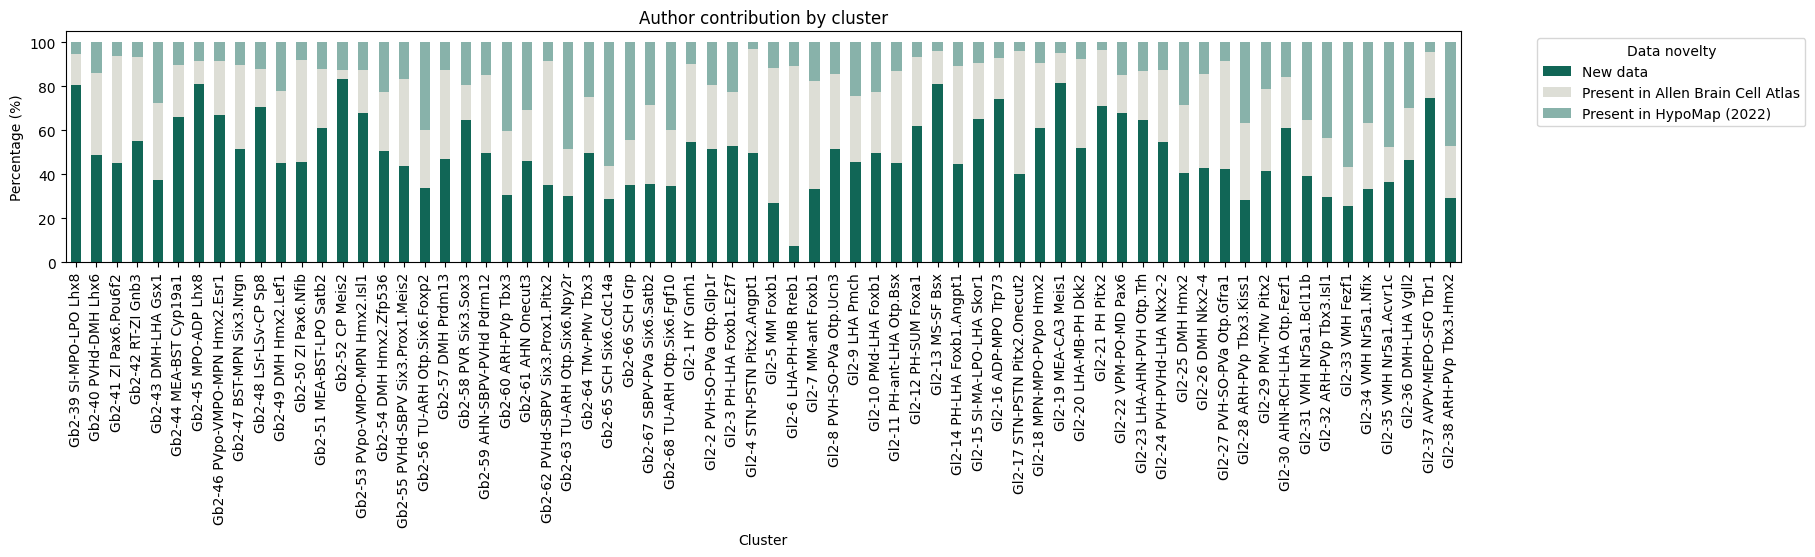

In [17]:

# Plot
ax = df_donor_subclass.plot(
    kind="bar",
    stacked=True,
    figsize=(18, 3),
    color=[color_map_donor_subclass[col] for col in df_donor_subclass.columns]
)

plt.ylabel("Percentage (%)")
plt.xlabel("Cluster")
plt.title("Author contribution by cluster")
plt.legend(title="Data novelty", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## num subclusters

In [18]:
num_sub_lvl5 = labelmat.loc[
    ~labelmat["L2_descr"].str.contains("NN"),
    ["L2_descr", "L5_descr"]
].astype(str).groupby("L2_descr")["L5_descr"].nunique().loc[leaf_labels_subclass]

num_sub_lvl5

L2_descr
Gb2-39 SI-MPO-LPO Lhx8       24
Gb2-40 PVHd-DMH Lhx6         12
Gb2-41 ZI Pax6.Pou6f2        42
Gb2-42 RT-ZI Gnb3             7
Gb2-43 DMH-LHA Gsx1          17
                             ..
Gl2-34 VMH Nr5a1.Nfix         6
Gl2-35 VMH Nr5a1.Acvr1c      22
Gl2-36 DMH-LHA Vgll2          5
Gl2-37 AVPV-MEPO-SFO Tbr1    18
Gl2-38 ARH-PVp Tbx3.Hmx2      1
Name: L5_descr, Length: 68, dtype: int64

In [19]:
heatmap_data_num_sub = pd.DataFrame([num_sub_lvl5.loc[leaf_labels_subclass].values], 
                            index=["Num subclusters"], 
                            columns=leaf_labels_subclass)


## spatial

In [20]:
relmass = pd.read_csv(RM_FP)

In [21]:
subclass_spatial = relmass.loc[(relmass.celltype_id.str[2] == "2") & (~relmass.celltype_id.str.contains("NN")), :]
subclass_spatial.drop(columns=["celltype_id", "celltype_abc_like", "flag"], inplace=True)
subclass_spatial = subclass_spatial.set_index("celltype_descr")
subclass_spatial = subclass_spatial.T
subclass_spatial = subclass_spatial.reset_index(names="allen_acronym").set_index("allen_acronym")
subclass_spatial.head(2)

/tmp/ipykernel_3184007/2337515987.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subclass_spatial.drop(columns=["celltype_id", "celltype_abc_like", "flag"], inplace=True)


celltype_descr,Gb2-39 SI-MPO-LPO Lhx8,Gb2-40 PVHd-DMH Lhx6,Gb2-41 ZI Pax6.Pou6f2,Gb2-42 RT-ZI Gnb3,Gb2-43 DMH-LHA Gsx1,Gb2-44 MEA-BST Cyp19a1,Gb2-45 MPO-ADP Lhx8,Gb2-46 PVpo-VMPO-MPN Hmx2.Esr1,Gb2-47 BST-MPN Six3.Nrgn,Gb2-48 LSr-LSv-CP Sp8,...,Gl2-35 VMH Nr5a1.Acvr1c,Gl2-36 DMH-LHA Vgll2,Gl2-37 AVPV-MEPO-SFO Tbr1,Gl2-38 ARH-PVp Tbx3.Hmx2,Gl2-4 STN-PSTN Pitx2.Angpt1,Gl2-5 MM Foxb1,Gl2-6 LHA-PH-MB Rreb1,Gl2-7 MM-ant Foxb1,Gl2-8 PVH-SO-PVa Otp.Ucn3,Gl2-9 LHA Pmch
allen_acronym,,,,,,,,,,,,,,,,,,,,,
TMv,0.000212,0.000215,0.000170,0.000026,0.002344,0.000222,0.000064,0.000177,0.000257,0.000184,...,0.001479,0.000346,0.000515,0.002892,0.000570,0.000923,0.003179,0.000192,0.000302,0.004058
int,0.020862,0.047460,0.015136,0.064585,0.003957,0.002738,0.003549,0.000771,0.001035,0.007291,...,0.001750,0.001259,0.003509,0.004838,0.046212,0.010638,0.008813,0.001594,0.000078,0.003255


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random

# --- Prepare data ---
# Step 1: Copy the relevant columns in dendrogram order
df_region = subclass_spatial.loc[:, leaf_labels_subclass].copy()

# Step 2: Remove lowercase and 'HY' entries
df_region = df_region[~df_region.index.to_series().apply(lambda x: x.islower())]
df_region = df_region[~df_region.index.to_series().isin(["HY", "V3"])]

# Step 3: Normalize columns (L1 norm)
df_region = df_region.div(df_region.sum(axis=0), axis=1)

# Step 4: Zero out values below 10%
# df_region[df_region < 0.1] = 0
# df_region[df_region == 0] = 0

def threshold_keep_topk(df, threshold=0.1, top_k=1):
    df = df.copy()

    for col in df.columns:
        if (df[col] < threshold).all():
            top = df[col].nlargest(top_k)
            df[col] = 0
            df.loc[top.index, col] = top.values
        else:
            df.loc[df[col] < threshold, col] = 0

    return df

df_region = threshold_keep_topk(df_region, threshold=0.1, top_k=1)

# Step 5: Add "rest" row
rest_row = 1 - df_region.sum(axis=0)
df_region.loc['Regions with < 10%'] = rest_row

# Step 6: Drop rows with all zero
df_region = df_region.loc[df_region.sum(axis=1) > 0, :]

# Step 7: Convert to %
df_region = df_region * 100

clusters_region = df_region.columns.tolist()
regions = df_region.index.tolist()

# ===================== Generate Unique Color Map =====================

# Exclude "Regions with < 10%" before generating palette
region_main = [r for r in regions if r != "Regions with < 10%"]

# Generate a large qualitative palette using husl for max distinguishability
palette_region = sns.color_palette("husl", len(region_main))

# Shuffle for visual distinction (optional)
random.seed(5)
random.shuffle(palette_region)

# Map colors
color_map_region = dict(zip(region_main, palette_region))
color_map_region["Regions with < 10%"] = "white"

# Optional: get the list of colors for use in legends or stacked plots
colors_region = [color_map_region[r] for r in regions]

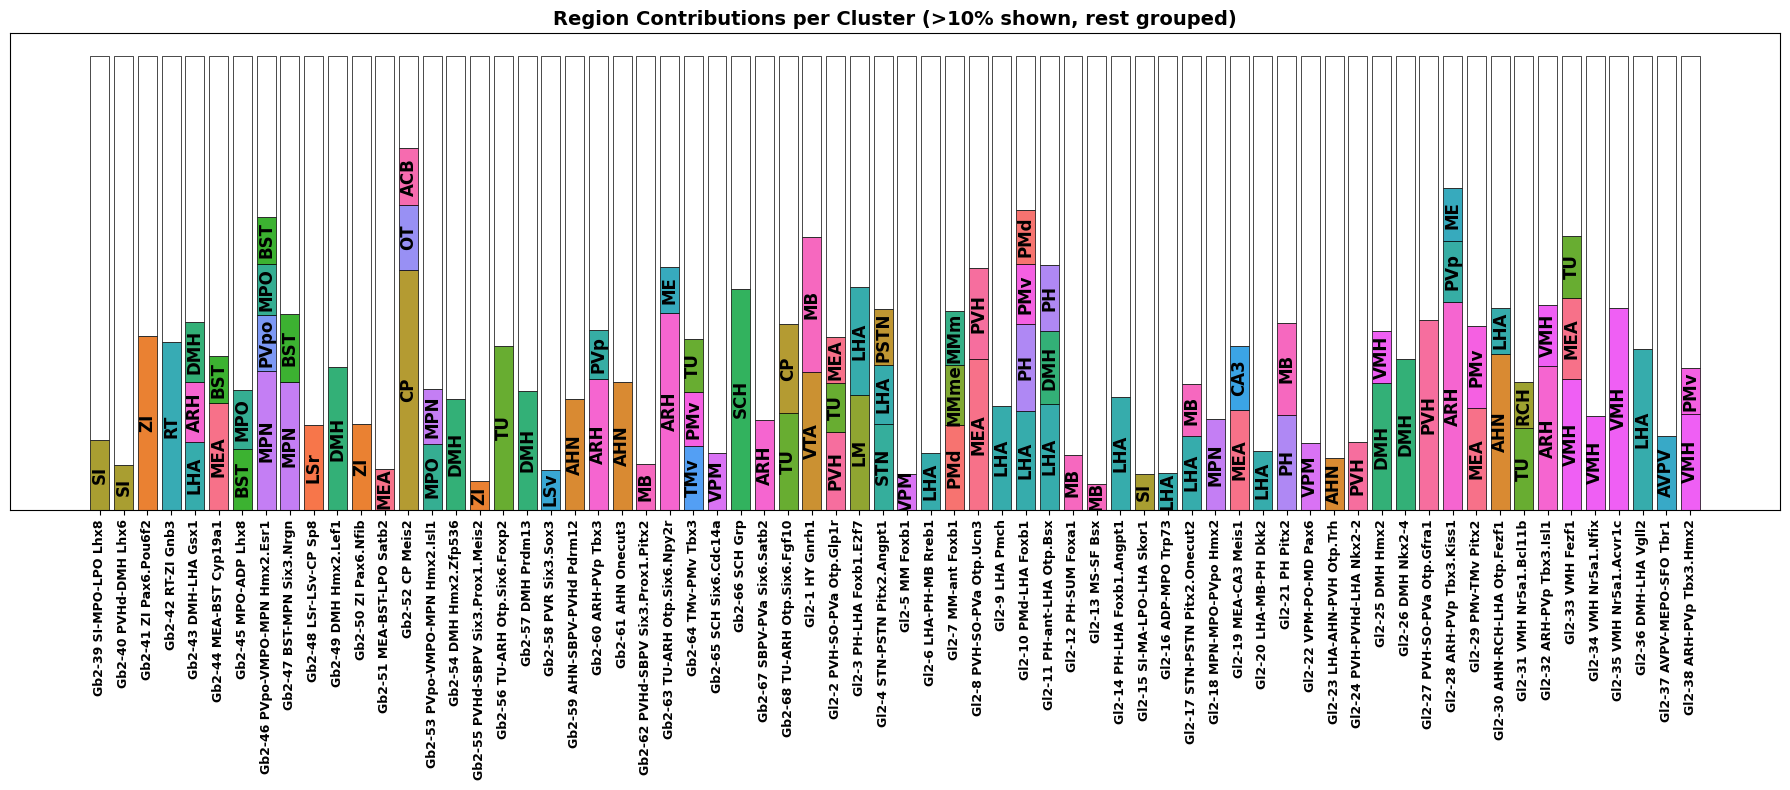

In [23]:

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 8))

# X positions
x = np.arange(len(clusters_region))

# Initialize bottom stack
bottom = np.zeros(len(clusters_region))

# Plot manually per cluster with per-cluster sorting
for i, cluster in enumerate(clusters_region):
    # Get the values for this cluster
    values = df_region[cluster]

    # Separate rest row
    if "Regions with < 10%" in values:
        rest_val = values["Regions with < 10%"]
        values_no_rest = values.drop("Regions with < 10%")
    else:
        rest_val = 0
        values_no_rest = values

    # Sort remaining regions by descending value
    values_sorted = values_no_rest.sort_values(ascending=False)

    # Now add the rest row at the end
    if rest_val > 0:
        values_sorted["Regions with < 10%"] = rest_val

    # Plot each region
    for region in values_sorted.index:
        height = values_sorted[region]
        if height > 0:
            ax.bar(
                x[i], height,
                bottom=bottom[i],
                color=color_map_region[region],
                edgecolor='black',
                linewidth=0.5,
                width=0.8
            )

            # Annotate if not "rest" and tall enough
            if region != "Regions with < 10%" and height > 3:
                ax.text(
                    x[i], bottom[i] + height / 2, region,
                    ha='center', va='center',
                    rotation=90,
                    fontsize=12,
                    fontweight='bold',
                    color='black',
                    clip_on=True
                )

            # Update bottom
            bottom[i] += height

# ---- Aesthetics ----
ax.set_xticks(x)
ax.set_xticklabels(clusters_region, rotation=90, ha='center', fontsize=9, weight='bold')
ax.set_yticks([])
ax.set_ylabel("")
ax.set_xlabel("")


plt.title("Region Contributions per Cluster (>10% shown, rest grouped)", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


### spatial QC

In [24]:
warnings = relmass.loc[(relmass.celltype_id.str[2] == "2") & (~relmass.celltype_id.str.contains("NN")), ["celltype_descr", "flag"]]
warnings.flag = warnings.flag.fillna("None")

In [25]:
warnings.head(2)

,celltype_descr,flag
6,Gb2-39 SI-MPO-LPO Lhx8,None
7,Gb2-40 PVHd-DMH Lhx6,None


In [26]:
color_map_warning_cat = {

  "None": "#155b0c",
  "Shape": "#C3C400",
  "Signal": "#EFC400",
  "Signal and shape": "#FF9E00",
  "No cells": "#FF4100",

    } 

In [27]:
# Step 1: Get the warning categories for selected clusters AND sort to match leaf_labels_gsx order
category_warning = warnings.set_index("celltype_descr").loc[leaf_labels_subclass, "flag"]

# Step 2: Convert to categorical and drop unused categories
warning_categories = category_warning.astype("category").cat.remove_unused_categories()

# Step 3: Get numeric codes
category_codes_warning = warning_categories.cat.codes

# Step 4: Build 1-row heatmap input — now columns are correctly ordered
heatmap_warning = pd.DataFrame([category_codes_warning.values], columns=leaf_labels_subclass)

# Step 5: Get correct category order (used categories only)
category_order_warning = warning_categories.cat.categories

# Step 6: Build colormap
cmap_warning = ListedColormap([color_map_warning_cat[c] for c in category_order_warning])

# Reverse x-axis (column) order
heatmap_warning = heatmap_warning[heatmap_warning.columns[::-1]]


/tmp/ipykernel_3184007/3920754635.py:24: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


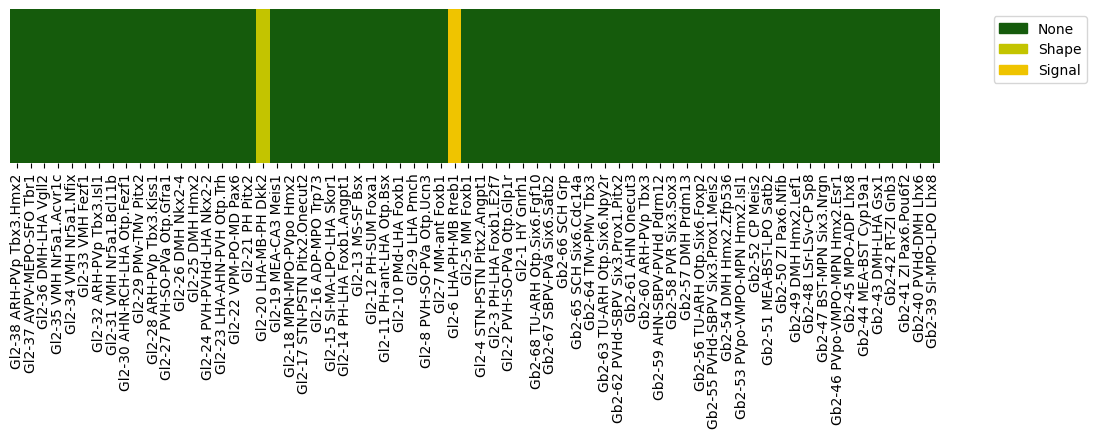

In [28]:

# Step 7: Plot
plt.figure(figsize=(12, 2))
sns.heatmap(
    heatmap_warning,
    cmap=cmap_warning,
    cbar=False,
    xticklabels=True,
    yticklabels=False
)

# Optional legend
import matplotlib.patches as mpatches
legend_handles = [
    mpatches.Patch(color=color_map_warning_cat[c], label=c)
    for c in category_order_warning
]
plt.legend(
    handles=legend_handles,
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    #title='HM3D to ABC Supertypes Mapping Category'
)

plt.tight_layout()
plt.show()


# Combining the above

## Horizontal

To be used for powerpoint slides for intance

In [29]:
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# import seaborn as sns
# import numpy as np
# from matplotlib.patches import Patch

# # ==== CONFIG ====
# fig = plt.figure(figsize=(18, 7), dpi=300)

# leaf_labels = leaf_labels_subclass[::-1]  # Ensure this is precomputed
# x = list(range(len(leaf_labels)))   # Used for manual bar plots

# gs = gridspec.GridSpec(
#     nrows=5, ncols=2,
#     width_ratios=[0.95, 0.05],
#     height_ratios=[0.4,   0.1, 0.25,0.1,  1.1, ],
#     hspace=0.05, wspace=0.05
# )

# # ===================== 1. Dendrogram =====================
# ax_dendro = fig.add_subplot(gs[0, 0])
# dendro = plot_colored_dendrogram(Z_subclass, idx_to_l2, l2_to_color, linewidth=3, ax=ax_dendro)
# ax_dendro.set_xticklabels(leaf_labels, fontweight='bold', rotation=90)
# ax_dendro.set_ylim(0.2, 0.35)
# ax_dendro.invert_xaxis()
# sns.despine(ax=ax_dendro, left=True, bottom=True)

# # Remove all y ticks and axis labels
# ax_dendro.set_yticks([])
# ax_dendro.set_ylabel("")
# ax_dendro.set_xlabel("")

# tick_labels = [tick.get_text() for tick in ax_dendro.get_xticklabels()]
# tick_positions = ax_dendro.get_xticks()
# label_to_x = dict(zip(tick_labels, tick_positions))


# ax_dendro.vlines(x=label_to_x["Gb2-40 PVHd-DMH Lhx6"], 
#         ymin = 0.3, ymax=1,
#         color=l2_to_color["Gb2-40 PVHd-DMH Lhx6"], linestyle='-', linewidth=3)
# ax_dendro.vlines(x=label_to_x["Gl2-2 PVH-SO-PVa Otp.Glp1r"], 
#         ymin = 0.3, ymax=1,
#         color=l2_to_color["Gl2-2 PVH-SO-PVa Otp.Glp1r"], linestyle='-', linewidth=3)

# ax_dendro.set_xticks([])

# # ===================== 2. Number of Subclusters Heatmap =====================
# ax_num_subclusters = fig.add_subplot(gs[1, 0])
# heat_data = heatmap_data_num_sub[leaf_labels[::-1]]

# sns.heatmap(
#     heat_data,
#     cmap="copper",
#     cbar=False,
#     xticklabels=True,
#     yticklabels=False,
#     linewidths=0.5,
#     linecolor='black',
#     ax=ax_num_subclusters,
#     annot=True,
#     fmt="d",
#     annot_kws={"fontsize": 8, "weight": "bold", "color": "white", "va": "center", "ha": "center"}
# )

# ax_num_subclusters.set_xticks([])
# ax_num_subclusters.set_yticks([])
# ax_num_subclusters.set_xlabel("")
# sns.despine(ax=ax_num_subclusters, left=True, bottom=True)

# # ===================== Bar Drawing Function =====================
# def draw_manual_stacked_bars(ax, df, color_map, cluster_order, category_order=None, bar_width=0.8, annotate=False):
#     x_positions = list(range(len(cluster_order)))
#     bottom = np.zeros(len(cluster_order))
#     all_categories = category_order if category_order else list(color_map.keys())

#     for cat in all_categories:
#         if cat not in df.columns:
#             df[cat] = 0

#     df = df[all_categories].loc[cluster_order].fillna(0)
#     handles = []

#     for cat in all_categories:
#         values = df[cat].values
#         bars = ax.bar(
#             x_positions, values,
#             bottom=bottom,
#             color=color_map[cat],
#             edgecolor='black',
#             linewidth=0.5,
#             width=bar_width,
#             label=cat
#         )

#         if annotate:
#             for xi, yi, h in zip(x_positions, bottom, values):
#                 if h > 5:
#                     ax.text(
#                         xi, yi + h / 2,
#                         f"{cat}",
#                         ha='center', va='center',
#                         fontsize=8,
#                         rotation=90,
#                         weight='bold',
#                         color='black'
#                     )

#         bottom += values
#         handles.append(Patch(color=color_map[cat], label=cat))

#     ax.set_xlim(-0.5, len(cluster_order) - 0.5)
#     ax.set_xticks([])
#     ax.set_yticks([])
#     sns.despine(ax=ax, left=True, bottom=True)

#     return handles

# # ===================== 3. Donor Contribution =====================
# ax_donor = fig.add_subplot(gs[2, 0])
# donor_handles = draw_manual_stacked_bars(
#     ax_donor,
#     df_donor_subclass,
#     color_map_donor_subclass,
#     leaf_labels[::-1]
# )

# #ax_donor_leg = fig.add_subplot(gs[2, 1])
# ax_donor_leg = fig.add_axes([0.85, 0.57, 0.05, 0.15])  # adjust as needed
# ax_donor_leg.axis("off")
# ax_donor_leg.legend(
#     handles=donor_handles,
#     title="Data novelty",
#     loc="center left",
#     frameon=False,
#     fontsize=8,
#     title_fontsize=9
# )
# ax_donor.set_xlabel("")



# # ===================== 4. Warning Category Heatmap =====================
# ax_warning = fig.add_subplot(gs[3, 0])
# sns.heatmap(
#     heatmap_warning.loc[:, leaf_labels[::-1]],  # ensure correct order
#     cmap=cmap_warning,
#     cbar=False,
#     xticklabels=False,
#     yticklabels=False,
#     linewidths=0.5,
#     linecolor='black',
#     ax=ax_warning
# )
# ax_warning.set_ylabel("")
# ax_warning.set_xlabel("")

# # ------------------------------
# # FIX: Center xticks on heatmap
# # ------------------------------
# # n = len(leaf_labels[::-1])
# # ax_warning.set_xticks(np.arange(n) + 0.5)
# # ax_warning.set_xticklabels(leaf_labels[::-1], rotation=90, fontsize=8, fontweight='bold', ha='center')
# ax_warning.set_xticks([])
# sns.despine(ax=ax_warning, left=True, bottom=True)

# # ===================== Warning Category Legend =====================
# import matplotlib.patches as mpatches

# ax_warning_leg = fig.add_axes([0.85, 0.35, 0.01, 0.1])  # [left, bottom, width, height] in figure coords
# ax_warning_leg.axis("off")

# legend_handles = [
#     mpatches.Patch(color=color_map_warning_cat[c], label=c)
#     for c in category_order_warning
# ]

# ax_warning_leg.legend(
#     handles=legend_handles,
#     title="Flag",
#     loc="center left",
#     frameon=False,
#     fontsize=8,
#     title_fontsize=9
# )

# # ===================== 5. Region Contribution (no legend) =====================
# ax_region = fig.add_subplot(gs[4, 0])
# bottom = np.zeros(len(leaf_labels[::-1]))

# for i, cluster in enumerate(leaf_labels[::-1]):
#     values = df_region[cluster]
#     rest = values.get("Regions with < 10%", 0)
#     values_no_rest = values.drop("Regions with < 10%", errors="ignore")
#     values_sorted = values_no_rest.sort_values(ascending=False)

#     if rest > 0:
#         values_sorted["Regions with < 10%"] = rest

#     for region in values_sorted.index:
#         height = values_sorted[region]
#         if height > 0:
#             ax_region.bar(
#                 x[i], height,
#                 bottom=bottom[i],
#                 width=0.8,
#                 color=color_map_region[region],
#                 edgecolor='black',
#                 linewidth=0.5
#             )
#             if region != "Regions with < 10%" and height >= 10:
#             #if region != "Regions with < 10%" and height > 3:
#                 ax_region.text(
#                     x[i], bottom[i] + height / 2, region,
#                     ha='center', va='center',
#                     rotation=90,
#                     fontsize=8,
#                     fontweight='bold'
#                 )
#             elif region != "Regions with < 10%":
#                 # Label above the segment
#                 ax_region.text(
#                     x[i], bottom[i] + height / 2, 
#                     # x[i],
#                     # bottom[i] + height + 1,   # 1% above the segment
#                     region,
#                     ha="center",
#                     va="center",
#                     #va="bottom",
#                     rotation=90,
#                     fontsize=7,
#                     fontweight="bold",
#                 )
#             bottom[i] += height

# ax_region.set_xlim(-0.5, len(leaf_labels[::-1]) - 0.5)
# ax_region.set_xticks(range(len(leaf_labels[::-1])))
# ax_region.set_xticklabels(leaf_labels[::-1], rotation=90, fontsize=8, fontweight='bold', ha='center')
# ax_region.set_yticks([])
# #ax_region.set_xticks([])
# ax_region.set_xlabel("")
# sns.despine(ax=ax_region, left=True, bottom=True)


# # ===================== Final Formatting =====================
# # Apply bold formatting only to donor legend
# for leg_ax in [ax_donor_leg, ax_warning_leg]:
#     legend = leg_ax.get_legend()
#     if legend:
#         legend.get_title().set_fontweight('bold')
#         for text in legend.get_texts():
#             text.set_fontweight('bold')

# plt.tight_layout()
# plt.savefig(OUTDIR /  "clusterinfo_subclass_tree_horizontal.pdf", dpi=300, bbox_inches="tight")
# plt.show()


## Vertical

/tmp/ipykernel_3184007/1210154632.py:286: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


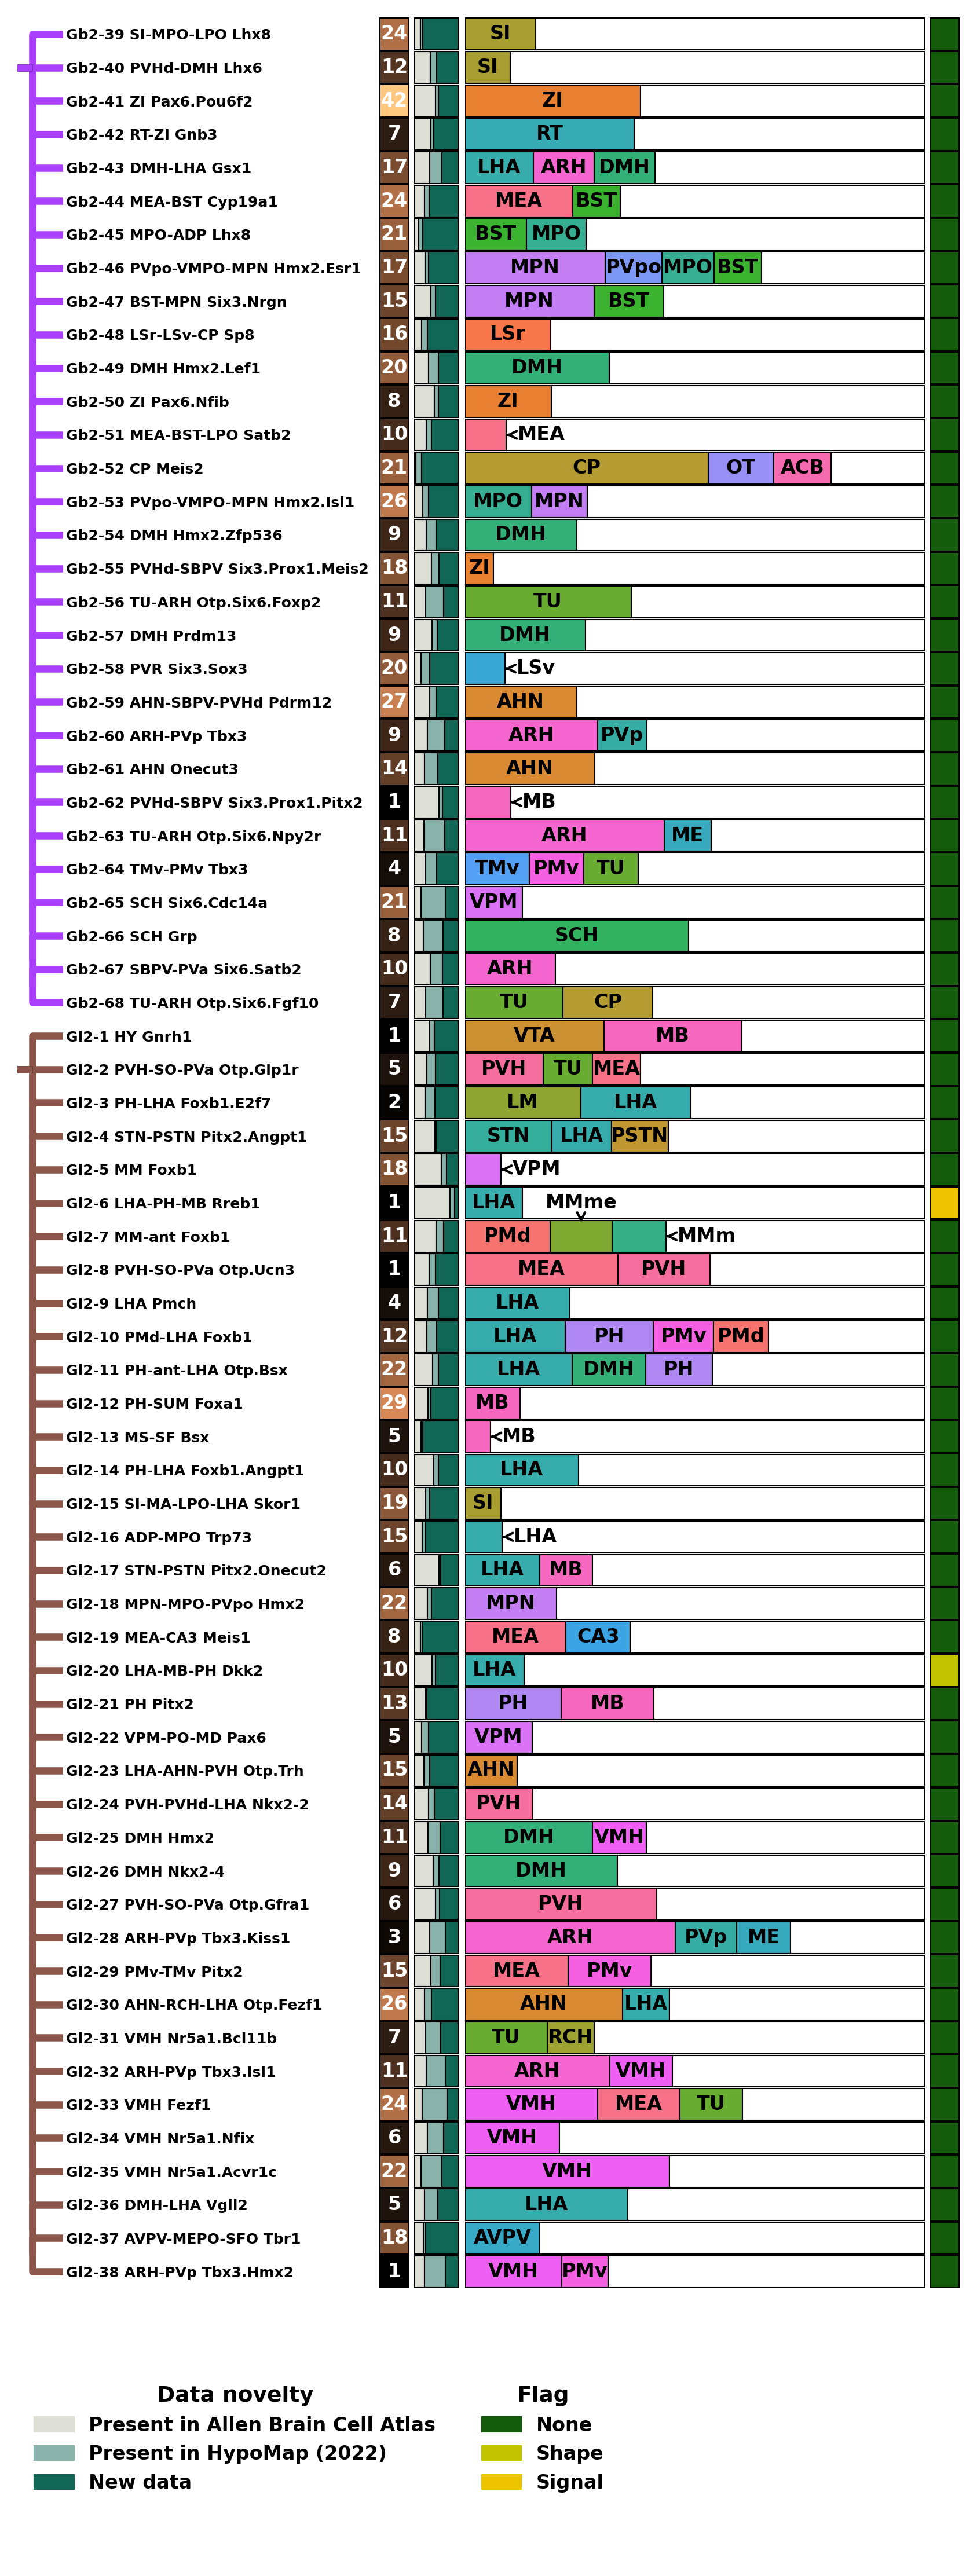

In [69]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

# ==== CONFIG ====
fig = plt.figure(figsize=(7, 19), dpi=300)

leaf_labels = leaf_labels_subclass[::-1]  # Ensure this is precomputed
y = list(range(len(leaf_labels)))   # Swapped from x -> y for horizontal layout

gs = gridspec.GridSpec(
    nrows=2, ncols=6,
    width_ratios=[0.15, 1, 0.1, 0.15, 1.5,  0.1,],
    height_ratios=[0.95, 0.1],
    hspace=0.025, wspace=0.03
)

# ===================== 1. Dendrogram =====================
ax_dendro = fig.add_subplot(gs[0, 0])
dendro = plot_colored_dendrogram(Z_subclass, idx_to_l2, l2_to_color, linewidth=3, ax=ax_dendro, orientation='left')
ax_dendro.set_yticklabels(leaf_labels, fontweight='bold', rotation=0)
ax_dendro.tick_params(axis='y', pad=1, length=0) 
ax_dendro.set_xlim(0.35, 0.2)
sns.despine(ax=ax_dendro, left=True, bottom=True)
ax_dendro.set_xticks([])
ax_dendro.set_ylabel("")
ax_dendro.set_xlabel("")

tick_labels = [tick.get_text() for tick in ax_dendro.get_yticklabels()]
tick_positions = ax_dendro.get_yticks()
label_to_y = dict(zip(tick_labels, tick_positions))

ax_dendro.hlines(y=label_to_y["Gb2-40 PVHd-DMH Lhx6"], 
        xmin = 0.3, xmax=1,
        color=l2_to_color["Gb2-40 PVHd-DMH Lhx6"], linestyle='-', linewidth=3)
ax_dendro.hlines(y=label_to_y["Gl2-2 PVH-SO-PVa Otp.Glp1r"], 
        xmin = 0.3, xmax=1,
        color=l2_to_color["Gl2-2 PVH-SO-PVa Otp.Glp1r"], linestyle='-', linewidth=3)

#ax_dendro.set_yticks([])

# ===================== 2. Number of Subclusters Heatmap =====================
ax_num_subclusters = fig.add_subplot(gs[0, 2])
heat_data = heatmap_data_num_sub[leaf_labels[::-1]].T  # Transposed
sns.heatmap(
    heat_data,
    cmap="copper",
    cbar=False,
    xticklabels=False,
    yticklabels=True,
    linewidths=0.5,
    linecolor='black',
    ax=ax_num_subclusters,
    annot=True,
    fmt="d",
    annot_kws={"fontsize": 8, "weight": "bold", "color": "white", "va": "center", "ha": "center"}
)
ax_num_subclusters.set_xticks([])
ax_num_subclusters.set_yticks([])
ax_num_subclusters.set_ylabel("")
sns.despine(ax=ax_num_subclusters, left=True, bottom=True)


# ===================== Bar Drawing Function =====================
def draw_manual_stacked_bars(ax, df, color_map, cluster_order, category_order=None, bar_height=0.95, annotate=False):
    y_positions = list(range(len(cluster_order)))
    left = np.zeros(len(cluster_order))
    all_categories = category_order if category_order else list(color_map.keys())

    for cat in all_categories:
        if cat not in df.columns:
            df[cat] = 0

    df = df[all_categories].loc[cluster_order].fillna(0)
    handles = []

    for cat in all_categories:
        values = df[cat].values
        bars = ax.barh(
            y_positions, values,
            left=left,
            color=color_map[cat],
            edgecolor='black',
            linewidth=0.5,
            height=bar_height,
            label=cat
        )

        if annotate:
            for yi, xi, w in zip(y_positions, left, values):
                if w > 5:
                    ax.text(
                        xi + w / 2, yi,
                        f"{cat}",
                        va='center', ha='center',
                        fontsize=8,
                        rotation=0,
                        weight='bold',
                        color='black'
                    )

        left += values
        handles.append(Patch(color=color_map[cat], label=cat))

    ax.set_ylim(-0.5, len(cluster_order) - 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax, left=True, bottom=True)

    return handles

# ===================== 3. Donor Contribution =====================
ax_donor = fig.add_subplot(gs[0, 3])
donor_handles = draw_manual_stacked_bars(
    ax_donor,
    df_donor_subclass,
    color_map_donor_subclass,
    leaf_labels
)

ax_donor_leg = fig.add_subplot(gs[1, 0])
ax_donor_leg.axis("off")
ax_donor_leg.legend(
    handles=donor_handles,
    title="Data novelty",
    loc="center left",
    frameon=False,
    fontsize=8,
    title_fontsize=9
)
ax_donor.set_xlabel("")

# ===================== 4. Region Contribution =====================
ax_region = fig.add_subplot(gs[0, 4])
bottom = np.zeros(len(leaf_labels[::-1]))

for i, cluster in enumerate(leaf_labels):
    values = df_region[cluster]
    rest = values.get("Regions with < 10%", 0)
    values_no_rest = values.drop("Regions with < 10%", errors="ignore")
    values_sorted = values_no_rest.sort_values(ascending=False)

    if rest > 0:
        values_sorted["Regions with < 10%"] = rest

    for region in values_sorted.index:
        width = values_sorted[region]
        if width > 0:
            ax_region.barh(
                y[i], width,
                left=bottom[i],
                height=0.95,
                color=color_map_region[region],
                edgecolor='black',
                linewidth=0.5
            )
            #if region != "Regions with < 10%" and width > 3:
            if region != "Regions with < 10%" and width >= 10:
                if region == "MMme":
                    # text centered above the bar, arrow pointing straight down
                    ax_region.annotate(
                        region,
                        xy=(bottom[i] + width / 2, y[i] + 0.4),         # arrow tip: top edge of the bar
                        xytext=(bottom[i] + width / 2, y[i] + 1),        # text centered one row above
                        ha='center', va='center',
                        fontsize=8, fontweight='bold',
                        arrowprops=dict(
                            arrowstyle="->",
                            color="black",
                            linewidth=1,
                            shrinkA=5, shrinkB=0,
                        ),
                        annotation_clip=False,
                    )
                elif region == "MMm":
                    # text right of the bar, arrow pointing straight left
                    ax_region.annotate(
                        region,
                        xy=(bottom[i] + width, y[i]),                    # arrow tip: right edge of the bar
                        xytext=(bottom[i] + width + 2.5, y[i]),            # text right of the bar
                        ha='left', va='center',
                        fontsize=8, fontweight='bold',
                        arrowprops=dict(
                            arrowstyle="->",
                            color="black",
                            linewidth=1,
                            shrinkA=2, shrinkB=0,
                            relpos=(0, 0.5),
                        ),
                        annotation_clip=False,
                    )
                else:
                    fontsize = 8#6
                    ax_region.text(
                    bottom[i] + width/2, y[i], region,
                    ha='center', va='center',
                    rotation=0,
                    fontsize=fontsize,
                    fontweight='bold'
                )


            elif region != "Regions with < 10%":
                if region in ["ZI", "SI"]:
                    fontsize = 8#6
                    ax_region.text(
                    bottom[i] + width/2, y[i], region,
                    ha='center', va='center',
                    rotation=0,
                    fontsize=fontsize,
                    fontweight='bold'
                )
                else:
                    ax_region.annotate(
                        region,
                        xy=(bottom[i] + width, y[i]),                    # arrow tip: right edge of the bar
                        xytext=(bottom[i] + width + 2.5, y[i]),            # text right of the bar
                        ha='left', va='center',
                        fontsize=8, fontweight='bold',
                        arrowprops=dict(
                            arrowstyle="->",
                            color="black",
                            linewidth=1,
                            shrinkA=2, shrinkB=0,
                            relpos=(0, 0.5),
                        ),
                        annotation_clip=False,
                    )
            bottom[i] += width

ax_region.set_ylim(-0.5, len(leaf_labels) - 0.5)
ax_region.margins(x=0)          # no padding left/right
ax_region.set_xlim(0, 100)      # optional: pin it explicitly if bars sum to 100
ax_region.set_yticks([])  # Remove default left-side labels
ax_region.set_xticks([])
sns.despine(ax=ax_region, left=True, bottom=True)

# ===================== 5. Warning Category Heatmap =====================
ax_warning = fig.add_subplot(gs[0, 5])
sns.heatmap(
    heatmap_warning.T.loc[leaf_labels[::-1]],  # ensure correct order
    cmap=cmap_warning,
    cbar=False,
    xticklabels=True,
    yticklabels=False,
    linewidths=0.5,
    linecolor='black',
    ax=ax_warning
)
ax_warning.set_ylabel("")
ax_warning.set_xlabel("")
ax_warning.set_xticks([])
sns.despine(ax=ax_warning, left=True, bottom=True)

# ===================== Warning Category Legend =====================
import matplotlib.patches as mpatches

ax_warning_leg = fig.add_subplot(gs[1, 4])
ax_warning_leg.axis("off")

legend_handles = [
    mpatches.Patch(color=color_map_warning_cat[c], label=c)
    for c in category_order_warning
]

ax_warning_leg.legend(
    handles=legend_handles,
    title="Flag",
    loc="center left",
    frameon=False,
    fontsize=8,
    title_fontsize=9
)


# ===================== Final Formatting =====================
for leg_ax in [ax_donor_leg, ax_warning_leg]:
    legend = leg_ax.get_legend()
    if legend:
        legend.get_title().set_fontweight('bold')
        for text in legend.get_texts():
            text.set_fontweight('bold')

plt.tight_layout()
plt.savefig(OUTDIR / "2b_clusterinfo_subclass_tree_vertical.pdf", dpi=300, bbox_inches="tight")
plt.show()


/tmp/ipykernel_3184007/3372635707.py:286: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


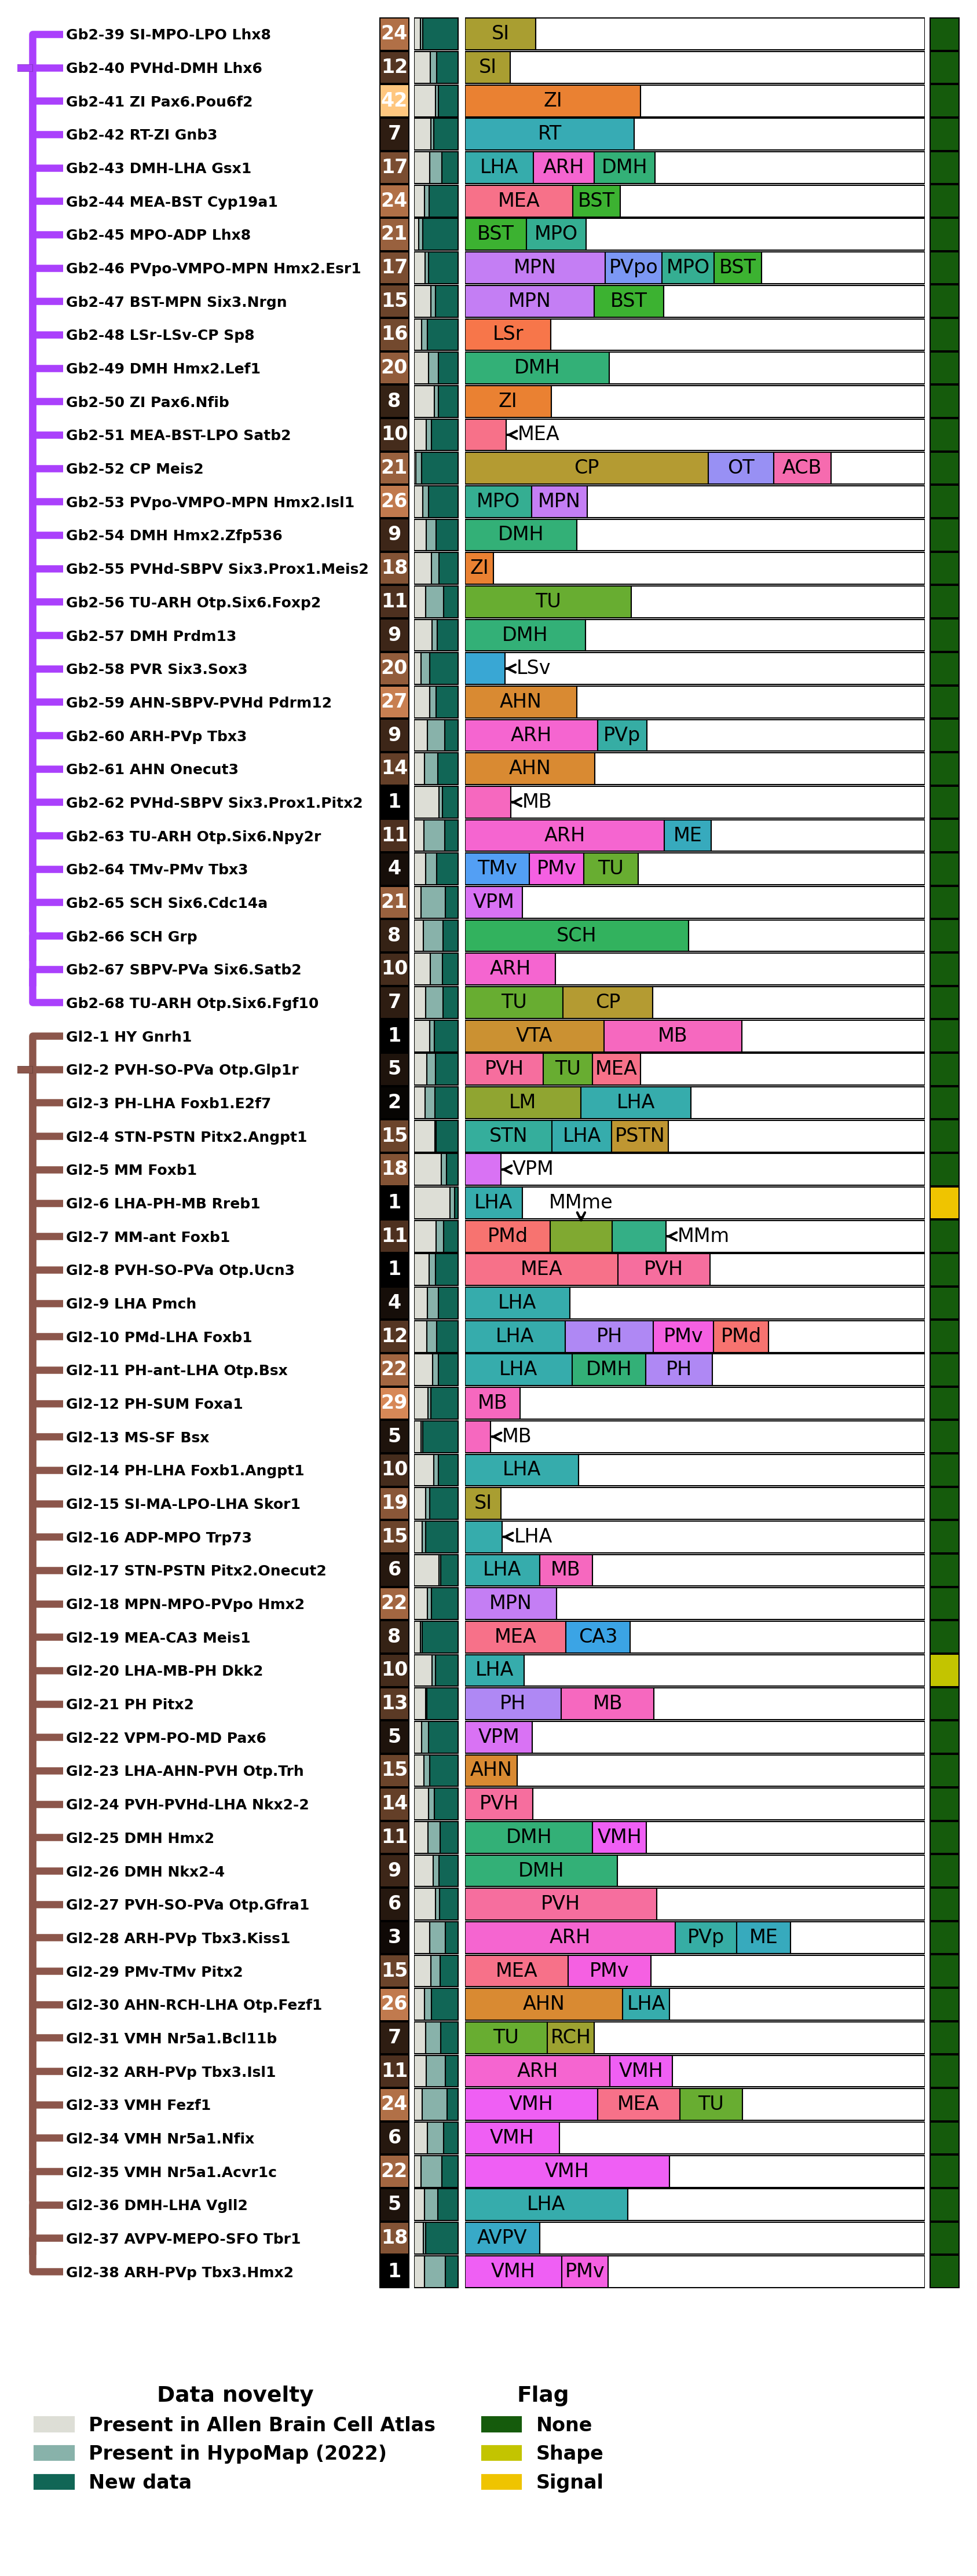

In [70]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

# ==== CONFIG ====
fig = plt.figure(figsize=(7, 19), dpi=300)

leaf_labels = leaf_labels_subclass[::-1]  # Ensure this is precomputed
y = list(range(len(leaf_labels)))   # Swapped from x -> y for horizontal layout

gs = gridspec.GridSpec(
    nrows=2, ncols=6,
    width_ratios=[0.15, 1, 0.1, 0.15, 1.5,  0.1,],
    height_ratios=[0.95, 0.1],
    hspace=0.025, wspace=0.03
)

# ===================== 1. Dendrogram =====================
ax_dendro = fig.add_subplot(gs[0, 0])
dendro = plot_colored_dendrogram(Z_subclass, idx_to_l2, l2_to_color, linewidth=3, ax=ax_dendro, orientation='left')
ax_dendro.set_yticklabels(leaf_labels, fontweight='bold', rotation=0)
ax_dendro.tick_params(axis='y', pad=1, length=0) 
ax_dendro.set_xlim(0.35, 0.2)
sns.despine(ax=ax_dendro, left=True, bottom=True)
ax_dendro.set_xticks([])
ax_dendro.set_ylabel("")
ax_dendro.set_xlabel("")

tick_labels = [tick.get_text() for tick in ax_dendro.get_yticklabels()]
tick_positions = ax_dendro.get_yticks()
label_to_y = dict(zip(tick_labels, tick_positions))

ax_dendro.hlines(y=label_to_y["Gb2-40 PVHd-DMH Lhx6"], 
        xmin = 0.3, xmax=1,
        color=l2_to_color["Gb2-40 PVHd-DMH Lhx6"], linestyle='-', linewidth=3)
ax_dendro.hlines(y=label_to_y["Gl2-2 PVH-SO-PVa Otp.Glp1r"], 
        xmin = 0.3, xmax=1,
        color=l2_to_color["Gl2-2 PVH-SO-PVa Otp.Glp1r"], linestyle='-', linewidth=3)

#ax_dendro.set_yticks([])

# ===================== 2. Number of Subclusters Heatmap =====================
ax_num_subclusters = fig.add_subplot(gs[0, 2])
heat_data = heatmap_data_num_sub[leaf_labels[::-1]].T  # Transposed
sns.heatmap(
    heat_data,
    cmap="copper",
    cbar=False,
    xticklabels=False,
    yticklabels=True,
    linewidths=0.5,
    linecolor='black',
    ax=ax_num_subclusters,
    annot=True,
    fmt="d",
    annot_kws={"fontsize": 8, "weight": "bold", "color": "white", "va": "center", "ha": "center"}
)
ax_num_subclusters.set_xticks([])
ax_num_subclusters.set_yticks([])
ax_num_subclusters.set_ylabel("")
sns.despine(ax=ax_num_subclusters, left=True, bottom=True)


# ===================== Bar Drawing Function =====================
def draw_manual_stacked_bars(ax, df, color_map, cluster_order, category_order=None, bar_height=0.95, annotate=False):
    y_positions = list(range(len(cluster_order)))
    left = np.zeros(len(cluster_order))
    all_categories = category_order if category_order else list(color_map.keys())

    for cat in all_categories:
        if cat not in df.columns:
            df[cat] = 0

    df = df[all_categories].loc[cluster_order].fillna(0)
    handles = []

    for cat in all_categories:
        values = df[cat].values
        bars = ax.barh(
            y_positions, values,
            left=left,
            color=color_map[cat],
            edgecolor='black',
            linewidth=0.5,
            height=bar_height,
            label=cat
        )

        if annotate:
            for yi, xi, w in zip(y_positions, left, values):
                if w > 5:
                    ax.text(
                        xi + w / 2, yi,
                        f"{cat}",
                        va='center', ha='center',
                        fontsize=8,
                        rotation=0,
                        weight='bold',
                        color='black'
                    )

        left += values
        handles.append(Patch(color=color_map[cat], label=cat))

    ax.set_ylim(-0.5, len(cluster_order) - 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax, left=True, bottom=True)

    return handles

# ===================== 3. Donor Contribution =====================
ax_donor = fig.add_subplot(gs[0, 3])
donor_handles = draw_manual_stacked_bars(
    ax_donor,
    df_donor_subclass,
    color_map_donor_subclass,
    leaf_labels
)

ax_donor_leg = fig.add_subplot(gs[1, 0])
ax_donor_leg.axis("off")
ax_donor_leg.legend(
    handles=donor_handles,
    title="Data novelty",
    loc="center left",
    frameon=False,
    fontsize=8,
    title_fontsize=9
)
ax_donor.set_xlabel("")

# ===================== 4. Region Contribution =====================
ax_region = fig.add_subplot(gs[0, 4])
bottom = np.zeros(len(leaf_labels[::-1]))

for i, cluster in enumerate(leaf_labels):
    values = df_region[cluster]
    rest = values.get("Regions with < 10%", 0)
    values_no_rest = values.drop("Regions with < 10%", errors="ignore")
    values_sorted = values_no_rest.sort_values(ascending=False)

    if rest > 0:
        values_sorted["Regions with < 10%"] = rest

    for region in values_sorted.index:
        width = values_sorted[region]
        if width > 0:
            ax_region.barh(
                y[i], width,
                left=bottom[i],
                height=0.95,
                color=color_map_region[region],
                edgecolor='black',
                linewidth=0.5
            )
            #if region != "Regions with < 10%" and width > 3:
            if region != "Regions with < 10%" and width >= 10:
                if region == "MMme":
                    # text centered above the bar, arrow pointing straight down
                    ax_region.annotate(
                        region,
                        xy=(bottom[i] + width / 2, y[i] + 0.4),         # arrow tip: top edge of the bar
                        xytext=(bottom[i] + width / 2, y[i] + 1),        # text centered one row above
                        ha='center', va='center',
                        fontsize=8, #fontweight='bold',
                        arrowprops=dict(
                            arrowstyle="->",
                            color="black",
                            linewidth=1,
                            shrinkA=5, shrinkB=0,
                        ),
                        annotation_clip=False,
                    )
                elif region == "MMm":
                    # text right of the bar, arrow pointing straight left
                    ax_region.annotate(
                        region,
                        xy=(bottom[i] + width, y[i]),                    # arrow tip: right edge of the bar
                        xytext=(bottom[i] + width + 2.5, y[i]),            # text right of the bar
                        ha='left', va='center',
                        fontsize=8, #fontweight='bold',
                        arrowprops=dict(
                            arrowstyle="->",
                            color="black",
                            linewidth=1,
                            shrinkA=2, shrinkB=0,
                            relpos=(0, 0.5),
                        ),
                        annotation_clip=False,
                    )
                else:
                    fontsize = 8#6
                    ax_region.text(
                    bottom[i] + width/2, y[i], region,
                    ha='center', va='center',
                    rotation=0,
                    fontsize=fontsize,
                    #fontweight='bold'
                )


            elif region != "Regions with < 10%":
                if region in ["ZI", "SI"]:
                    fontsize = 8#6
                    ax_region.text(
                    bottom[i] + width/2, y[i], region,
                    ha='center', va='center',
                    rotation=0,
                    fontsize=fontsize,
                    #fontweight='bold'
                )
                else:
                    ax_region.annotate(
                        region,
                        xy=(bottom[i] + width, y[i]),                    # arrow tip: right edge of the bar
                        xytext=(bottom[i] + width + 2.5, y[i]),            # text right of the bar
                        ha='left', va='center',
                        fontsize=8, #fontweight='bold',
                        arrowprops=dict(
                            arrowstyle="->",
                            color="black",
                            linewidth=1,
                            shrinkA=2, shrinkB=0,
                            relpos=(0, 0.5),
                        ),
                        annotation_clip=False,
                    )
            bottom[i] += width

ax_region.set_ylim(-0.5, len(leaf_labels) - 0.5)
ax_region.margins(x=0)          # no padding left/right
ax_region.set_xlim(0, 100)      # optional: pin it explicitly if bars sum to 100
ax_region.set_yticks([])  # Remove default left-side labels
ax_region.set_xticks([])
sns.despine(ax=ax_region, left=True, bottom=True)

# ===================== 5. Warning Category Heatmap =====================
ax_warning = fig.add_subplot(gs[0, 5])
sns.heatmap(
    heatmap_warning.T.loc[leaf_labels[::-1]],  # ensure correct order
    cmap=cmap_warning,
    cbar=False,
    xticklabels=True,
    yticklabels=False,
    linewidths=0.5,
    linecolor='black',
    ax=ax_warning
)
ax_warning.set_ylabel("")
ax_warning.set_xlabel("")
ax_warning.set_xticks([])
sns.despine(ax=ax_warning, left=True, bottom=True)

# ===================== Warning Category Legend =====================
import matplotlib.patches as mpatches

ax_warning_leg = fig.add_subplot(gs[1, 4])
ax_warning_leg.axis("off")

legend_handles = [
    mpatches.Patch(color=color_map_warning_cat[c], label=c)
    for c in category_order_warning
]

ax_warning_leg.legend(
    handles=legend_handles,
    title="Flag",
    loc="center left",
    frameon=False,
    fontsize=8,
    title_fontsize=9
)


# ===================== Final Formatting =====================
for leg_ax in [ax_donor_leg, ax_warning_leg]:
    legend = leg_ax.get_legend()
    if legend:
        legend.get_title().set_fontweight('bold')
        for text in legend.get_texts():
            text.set_fontweight('bold')

plt.tight_layout()
plt.savefig(OUTDIR / "2b_clusterinfo_subclass_tree_vertical_regions_not_bold.pdf", dpi=300, bbox_inches="tight")
plt.show()
